In [90]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 1. Инициализация детектора SIFT и параметров

In [ ]:
# Настраиваем параметры для детекции
sift = cv2.SIFT_create(
    nfeatures=2000, # Максимальное число возвращаемых ключевых точек
    nOctaveLayers=3, # Число слоёв внутри каждой октавы гауссовой пирамиды
    contrastThreshold=0.03, # Порог для фильтрации слабых (низкоконтрастных) ключевых точек
    edgeThreshold=15, # Фильтр точек, лежащих на длинных гранях
    sigma=1.6 # Начальный параметр сигма для Гауссова сглаживания
)

In [92]:
# Названия 6 изображений
image_files = [
    "Bosmina longirostris 1.jpg", "Bosmina longirostris 2.jpg", "Bosmina longirostris 3.jpg",
    "Bosmina longirostris 4.jpg", "Bosmina longirostris 5.jpg", "Bosmina longirostris 6.jpg"
]

images = []
kp_list = []
des_list = []

In [93]:
# Выравниваем изображения (клюв направден влево у всех) и пОиск ключевых точек
for idx, path in enumerate(image_files):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        
    if idx in (1, 2, 4):
        img = cv2.flip(img, 1)
        
    images.append(img)
    kp, des = sift.detectAndCompute(img, None)
    kp_list.append(kp)
    des_list.append(des)
    print(f"Изображение {idx+1}: Найдено ключевых точек = {len(kp)}")

Изображение 1: Найдено ключевых точек = 2000
Изображение 2: Найдено ключевых точек = 2001
Изображение 3: Найдено ключевых точек = 2001
Изображение 4: Найдено ключевых точек = 2000
Изображение 5: Найдено ключевых точек = 2000
Изображение 6: Найдено ключевых точек = 272


### 2. Попарное сопоставление дескрипторов и фильтрация ненадёжных совпадений

In [94]:
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)

# Создаем структуру для отслеживания цепочек совпадений
num_imgs = len(images)
common_tracks = []

for kp1_idx in range(len(kp_list[0])):
    track = {0: kp1_idx}
    current_des = des_list[0][kp1_idx : kp1_idx + 1]
    for target_idx in range(1, num_imgs):
        if des_list[target_idx] is None:
            break
            
        matches = bf.match(current_des, des_list[target_idx])
        
        if len(matches) > 0:
            if matches[0].distance < 250.0:
                track[target_idx] = matches[0].trainIdx
            else:
                break
        else:
            break 
            
    if len(track) == num_imgs:
        common_tracks.append(track)

print(f"Успешно найдено общих сквозных точек: {len(common_tracks)}")


# Ищем 30 лучших
track_scores = []

for track in common_tracks:
    total_dist = 0
    kp0_idx = track[0]
    des0 = des_list[0][kp0_idx : kp0_idx + 1]
    
    for img_idx in range(1, num_imgs):
        kp_target_idx = track[img_idx]
        des_target = des_list[img_idx][kp_target_idx : kp_target_idx + 1]
        dist = np.linalg.norm(des0 - des_target)
        total_dist += dist
    track_scores.append((total_dist, track))
track_scores.sort(key=lambda x: x[0])

best_tracks = [track for score, track in track_scores[:30]]
print(f"Из {len(common_tracks)} точек успешно отобрано {len(best_tracks)} лучших")

Успешно найдено общих сквозных точек: 110
Из 110 точек успешно отобрано 30 лучших


### 3. Визуализация результатов

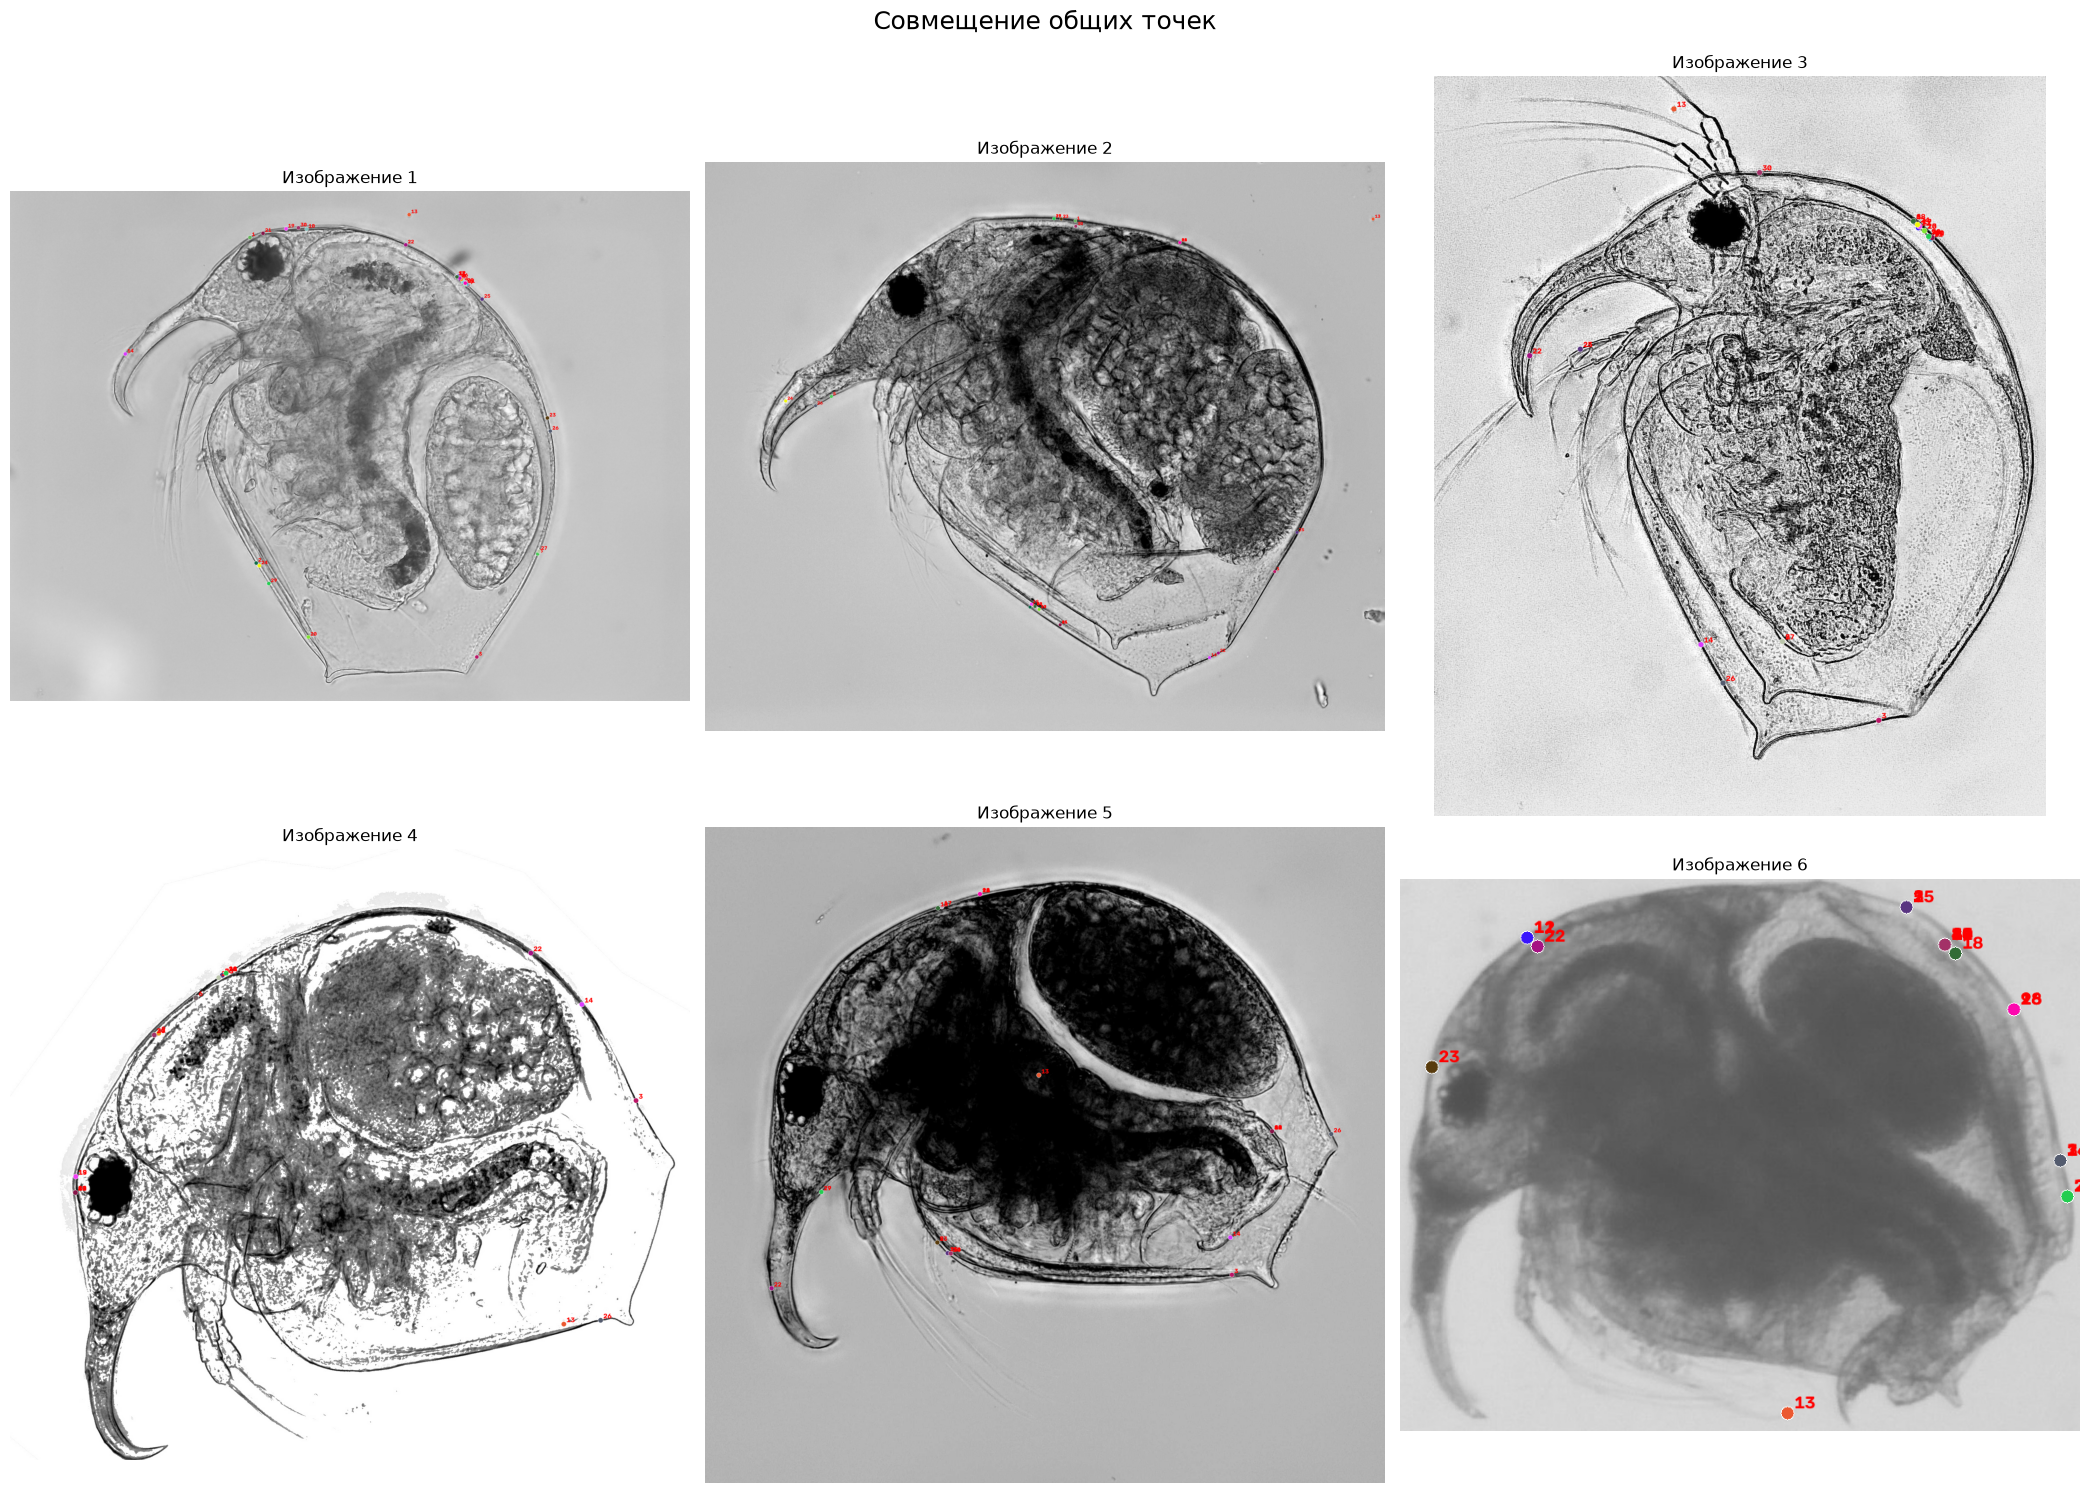

In [95]:
fig, axes = plt.subplots(2, 3, figsize=(21, 15))
axes = axes.ravel()

np.random.seed(42)
colors = np.random.randint(0, 255, size=(30, 3), dtype=int)

for i in range(num_imgs):
    out_img = cv2.cvtColor(images[i], cv2.COLOR_GRAY2RGB)
    
    for pt_num, track in enumerate(best_tracks):
        kp_idx = track[i]
        pt = kp_list[i][kp_idx].pt
        x, y = int(pt[0]), int(pt[1])
        
        color = [int(c) for c in colors[pt_num]]
        cv2.circle(out_img, (x, y), 7, color, -1)
        cv2.circle(out_img, (x, y), 8, (255, 255, 255), 1)
        cv2.putText(out_img, str(pt_num + 1), (x + 8, y - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 0, 0), 2, cv2.LINE_AA)
        
    axes[i].imshow(out_img)
    axes[i].set_title(f"Изображение {i+1}")
    axes[i].axis('off')

plt.tight_layout()
plt.suptitle("Совмещение общих точек", fontsize=18, y=1.02)
plt.show()